# TP 8 - NetworkX et Dijkstra

**Cours :** Structures de données et algorithmique - CPE Lyon, 3IRC, 2025/2026

Ce notebook poursuit la séance de travaux pratiques précédente :

1. découvrir les principaux objets de **NetworkX** sur le graphe de Petersen ;
2. charger un graphe pondéré et l'afficher ;
3. implémenter l'**algorithme de Dijkstra** avec une *liste* de sommets visités,
   puis avec un *ensemble*, et comparer les deux avec une version utilisant un
   tas binaire ;
4. préparer le calculateur d'itinéraires optionnel **OSMnx** (notebook séparé).

L'implémentation réutilisable se trouve dans `src/sda/tp08_networkx` ; le
notebook conserve le code visible étape par étape.

In [1]:
import math
import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

## 1. Le graphe de Petersen

NetworkX représente un graphe sous la forme d'un dictionnaire de dictionnaires.
Nous construisons le graphe de Petersen à partir de sa liste d'arêtes, puis nous
posons à la bibliothèque les questions du TD.

In [2]:
from sda.tp07_graphs.examples import PETERSEN_EDGES

G = nx.Graph()
G.add_edges_from(PETERSEN_EDGES)
print(G)
print("sommets :", sorted(G.nodes))
print("arêtes :", sorted(G.edges))

Graph with 10 nodes and 15 edges
sommets : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
arêtes : [(1, 3), (1, 4), (2, 4), (2, 5), (3, 5), (6, 1), (6, 7), (6, 10), (7, 2), (7, 8), (8, 3), (8, 9), (9, 4), (9, 10), (10, 5)]


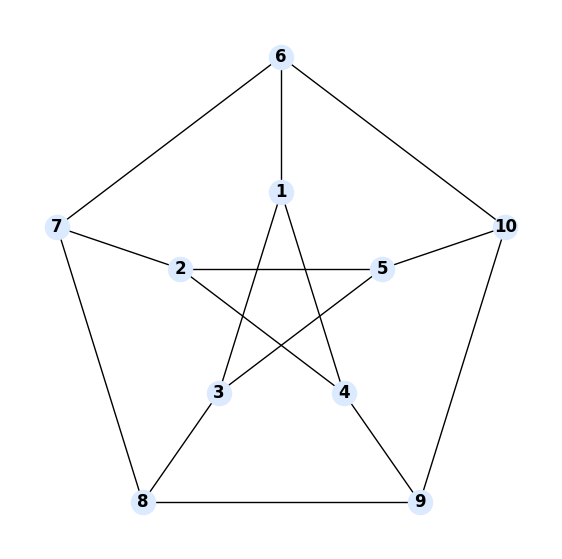

In [3]:
# Un dessin proche de la représentation habituelle en deux pentagones.
pos = {}
for index, vertex in enumerate([6, 7, 8, 9, 10]):
    angle = math.pi / 2 + 2 * math.pi * index / 5
    pos[vertex] = (math.cos(angle), math.sin(angle))
for index, vertex in enumerate([1, 2, 3, 4, 5]):
    angle = math.pi / 2 + 2 * math.pi * index / 5
    pos[vertex] = (0.45 * math.cos(angle), 0.45 * math.sin(angle))

plt.figure(figsize=(7, 7))
nx.draw_networkx(G, pos=pos, with_labels=True, node_color="#dbeafe", font_weight="bold")
plt.axis("off")
plt.show()

### Questions avec NetworkX

- Le graphe est-il orienté ?
- Quels sont ses sommets et ses arêtes ?
- Voisins de 2, degré de 9 ?
- Est-il régulier ? Connexe ?
- Matrices d'adjacence et d'incidence.
- Sous-graphe induit sur `{6, 3, 7, 8, 1, 5}`.

In [4]:
print("orienté :", G.is_directed())
print("voisins de 2 :", list(G.neighbors(2)))
print("degré de 9 :", G.degree[9])
print("degrés :", dict(G.degree))
print("régulier :", nx.is_regular(G))
print("connexe :", nx.is_connected(G))
print("biparti :", nx.is_bipartite(G))

orienté : False
voisins de 2 : [7, 5, 4]
degré de 9 : 3
degrés : {6: 3, 7: 3, 8: 3, 9: 3, 10: 3, 1: 3, 2: 3, 3: 3, 4: 3, 5: 3}
régulier : True
connexe : True
biparti : False


In [5]:
adjacency = nx.to_numpy_array(G, nodelist=sorted(G.nodes), dtype=int)
print("matrice d'adjacence :")
print(adjacency)

incidence = nx.incidence_matrix(G).todense()
print("dimensions de la matrice d'incidence :", incidence.shape)
print("sommes des colonnes :", np.asarray(incidence).sum(axis=0))

matrice d'adjacence :
[[0 0 1 1 0 1 0 0 0 0]
 [0 0 0 1 1 0 1 0 0 0]
 [1 0 0 0 1 0 0 1 0 0]
 [1 1 0 0 0 0 0 0 1 0]
 [0 1 1 0 0 0 0 0 0 1]
 [1 0 0 0 0 0 1 0 0 1]
 [0 1 0 0 0 1 0 1 0 0]
 [0 0 1 0 0 0 1 0 1 0]
 [0 0 0 1 0 0 0 1 0 1]
 [0 0 0 0 1 1 0 0 1 0]]


dimensions de la matrice d'incidence : (10, 15)
sommes des colonnes : [2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]


sommets induits : [1, 3, 5, 6, 7, 8]
arêtes induites : [(1, 3), (3, 5), (6, 1), (6, 7), (7, 8), (8, 3)]
degrés : {6: 2, 7: 2, 8: 2, 1: 2, 3: 3, 5: 1}


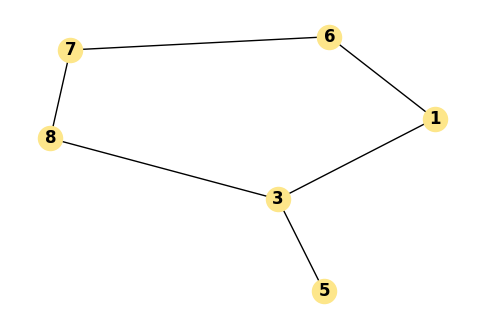

In [6]:
H = G.subgraph([6, 3, 7, 8, 1, 5])
print("sommets induits :", sorted(H.nodes))
print("arêtes induites :", sorted(H.edges))
print("degrés :", dict(H.degree))

plt.figure(figsize=(6, 4))
nx.draw_networkx(H, with_labels=True, node_color="#fde68a", font_weight="bold")
plt.axis("off")
plt.show()

## 2. Un graphe pondéré de TP

Le jeu de données `data/tp08_graph.txt` contient 20 sommets, 30 arêtes, des
poids compris entre 1 et 50, et il est connexe. Il est chargé avec la même
fonction `read_multiline_adjlist` que dans l'énoncé.

In [7]:
from sda.tp08_networkx.fixture import load_graph, START, TARGET

weighted = load_graph()
print(weighted)
print("connexe :", nx.is_connected(weighted))
print("poids de 0-8 :", weighted[0][8])
print("nombre d'arêtes :", weighted.number_of_edges())

Graph with 20 nodes and 30 edges
connexe : True
poids de 0-8 : {'weight': 36.0}
nombre d'arêtes : 30


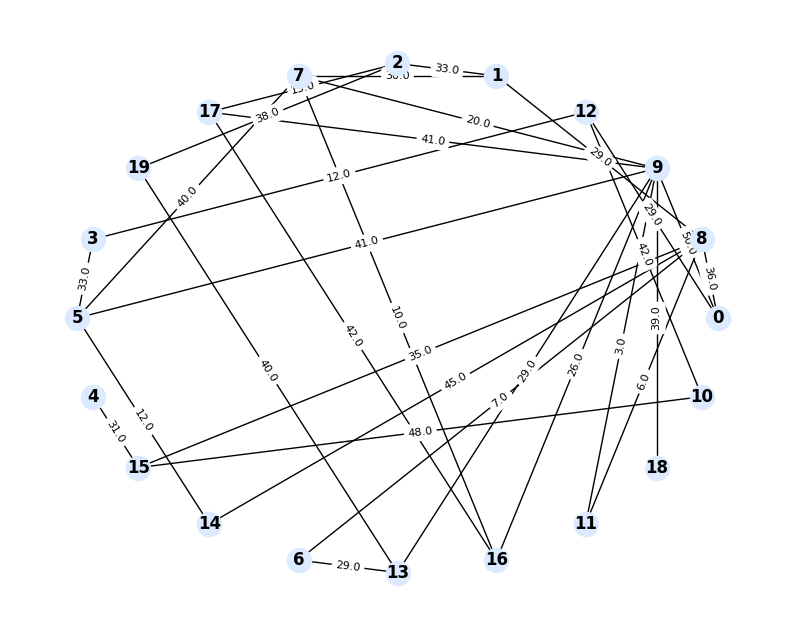

In [8]:
pos = nx.circular_layout(weighted)
plt.figure(figsize=(10, 8))
nx.draw_networkx(weighted, pos=pos, with_labels=True, node_color="#dbeafe", font_weight="bold")
labels = nx.get_edge_attributes(weighted, "weight")
nx.draw_networkx_edge_labels(weighted, pos=pos, edge_labels=labels, font_size=8)
plt.axis("off")
plt.show()

## 3. Dijkstra avec une liste de sommets visités

L'algorithme maintient :

- `distances[v]` : meilleure distance connue depuis la source ;
- `previous[v]` : prédécesseur sur le meilleur chemin ;
- `visited` : sommets dont la distance est définitive.

À chaque itération, nous sélectionnons le sommet non visité de plus petite
distance, puis nous relaxons ses arêtes. Conserver `visited` dans une **liste**
rend le test d'appartenance `v in visited` linéaire : le coût total devient
`O(V^2)` rien que pour ces tests.

In [9]:
def dijkstra1(graph, start, target):
    distances = {start: 0.0}
    previous = {}
    visited = []

    while True:
        candidates = [v for v in distances if v not in visited]
        if not candidates:
            break
        current = min(candidates, key=distances.get)
        if current == target:
            break
        visited.append(current)
        for neighbour, data in graph[current].items():
            if neighbour in visited:
                continue
            weight = data.get("weight", data.get("length", 1))
            candidate = distances[current] + weight
            if candidate < distances.get(neighbour, math.inf):
                distances[neighbour] = candidate
                previous[neighbour] = current

    if target not in distances:
        return math.inf, []
    path = [target]
    while path[-1] != start:
        path.append(previous[path[-1]])
    return distances[target], path[::-1]

In [10]:
distance, path = dijkstra1(weighted, START, TARGET)
print("longueur :", distance)
print("chemin :", path)

longueur : 112.0
chemin : [0, 8, 6, 13, 19]


## 4. Remplacer la liste par un ensemble

Un `set` fournit un test d'appartenance en `O(1)`. La recherche du minimum reste
linéaire en nombre de sommets, mais les tests d'appartenance coûteux
disparaissent. Le résultat doit être identique.

In [11]:
def dijkstra2(graph, start, target):
    distances = {start: 0.0}
    previous = {}
    visited = set()

    while True:
        candidates = [v for v in distances if v not in visited]
        if not candidates:
            break
        current = min(candidates, key=distances.get)
        if current == target:
            break
        visited.add(current)
        for neighbour, data in graph[current].items():
            if neighbour in visited:
                continue
            weight = data.get("weight", data.get("length", 1))
            candidate = distances[current] + weight
            if candidate < distances.get(neighbour, math.inf):
                distances[neighbour] = candidate
                previous[neighbour] = current

    if target not in distances:
        return math.inf, []
    path = [target]
    while path[-1] != start:
        path.append(previous[path[-1]])
    return distances[target], path[::-1]

In [12]:
print("dijkstra1:", dijkstra1(weighted, START, TARGET))
print("dijkstra2:", dijkstra2(weighted, START, TARGET))

dijkstra1: (112.0, [0, 8, 6, 13, 19])
dijkstra2: (112.0, [0, 8, 6, 13, 19])


## 5. Un tas binaire

Avec un tas, l'extraction du minimum et la relaxation d'une arête coûtent
`O(log V)`, pour un total de `O((V + E) log V)`. NetworkX ne propose pas de
diminution de clé (decrease-key), nous empilons donc une nouvelle paire lorsqu'une
distance s'améliore et nous ignorons les entrées périmées lorsqu'elles sont
extraites.

In [13]:
import heapq


def dijkstra_heap(graph, start, target):
    distances = {start: 0.0}
    previous = {}
    queue = [(0.0, start)]
    visited = set()

    while queue:
        distance, current = heapq.heappop(queue)
        if current in visited:
            continue
        visited.add(current)
        if current == target:
            break
        for neighbour, data in graph[current].items():
            if neighbour in visited:
                continue
            weight = data.get("weight", data.get("length", 1))
            candidate = distance + weight
            if candidate < distances.get(neighbour, math.inf):
                distances[neighbour] = candidate
                previous[neighbour] = current
                heapq.heappush(queue, (candidate, neighbour))

    if target not in distances:
        return math.inf, []
    path = [target]
    while path[-1] != start:
        path.append(previous[path[-1]])
    return distances[target], path[::-1]

In [14]:
print("tas :", dijkstra_heap(weighted, START, TARGET))
print("NetworkX :", nx.shortest_path_length(weighted, START, TARGET, weight="weight"))

tas : (112.0, [0, 8, 6, 13, 19])
NetworkX : 112.0


## 6. Mesure des temps des trois versions

Le graphe de TP est minuscule, la différence est donc faible. Sur un graphe
aléatoire de 400 sommets, le comportement quadratique du test d'appartenance
dans la liste devient visible.

In [15]:
def timed(algorithm, graph, start, target):
    begin = time.perf_counter()
    result = algorithm(graph, start, target)
    return result, time.perf_counter() - begin

for algorithm in (dijkstra1, dijkstra2, dijkstra_heap):
    (distance, path), elapsed = timed(algorithm, weighted, START, TARGET)
    print(f"{algorithm.__name__:>13}: {distance:>6} en {elapsed * 1e6:8.1f} us")

    dijkstra1:  112.0 en    112.9 us
    dijkstra2:  112.0 en     68.9 us
dijkstra_heap:  112.0 en     45.1 us


In [16]:
seed = 0
while True:
    large = nx.gnm_random_graph(400, 900, seed=seed)
    if nx.is_connected(large):
        break
    seed += 1
for source, target in large.edges():
    large[source][target]["weight"] = (source * 31 + target * 17) % 50 + 1

print(f"grand graphe : {large.number_of_nodes()} sommets, {large.number_of_edges()} arêtes")
print("longueur NetworkX :", nx.shortest_path_length(large, 0, 399, weight="weight"))
for algorithm in (dijkstra1, dijkstra2, dijkstra_heap):
    (distance, path), elapsed = timed(algorithm, large, 0, 399)
    print(f"{algorithm.__name__:>13}: {distance:>8} en {elapsed * 1e3:8.2f} ms")

grand graphe : 400 sommets, 900 arêtes
longueur NetworkX : 103
    dijkstra1:    103.0 en    53.33 ms
    dijkstra2:    103.0 en     4.70 ms
dijkstra_heap:    103.0 en     1.00 ms


## 7. Conclusion

- NetworkX rend immédiates la construction, l'inspection et le tracé d'un
  graphe, mais l'exercice demande d'écrire l'algorithme à la main.
- La **liste des sommets visités** est correcte mais ajoute un test en `O(V)` à
  l'intérieur de la boucle principale.
- L'**ensemble** supprime ce coût ; le terme `O(V^2)` restant provient de la
  recherche linéaire du minimum.
- Le **tas** réduit le coût total à `O((V + E) log V)`.
- Les trois versions renvoient le même plus court chemin.

L'application OSMnx (réseau routier de Lyon, géocodage, itinéraire et carte) se
trouve dans `tp08_osmnx_routing.ipynb`, car elle nécessite un accès à Internet
et le paquet optionnel `osmnx`.